# Week 5 — Day 2
# Decision Trees

Today we move from Logistic Regression to **Decision Trees**.

The main question is:

> How can a Machine Learning model make decisions by asking a series of questions about the data?


## Learning Objectives

By the end of this lesson, you will be able to:

- Define a Decision Tree.
- Explain nodes, branches, and leaves.
- Understand how a tree makes decisions.
- Train a `DecisionTreeClassifier`.
- Visualize a decision tree.
- Make predictions.
- Evaluate a decision tree.
- Understand `max_depth`.
- Explain overfitting in Decision Trees.
- Compare shallow and deep trees.
- Understand pruning at a beginner level.
- Compare Decision Trees with Logistic Regression.
- Apply Decision Trees to student and customer datasets.


## Why This Lesson Matters

Imagine a teacher trying to predict whether a student will pass.

Instead of calculating a complicated mathematical formula, the teacher might ask:

1. Did the student study more than 4 hours?
2. Is attendance above 70%?
3. If not, should the student be classified as Fail?

A Decision Tree works in a similar question-and-answer style.


## What is a Decision Tree?

**A Decision Tree is a supervised Machine Learning algorithm that makes predictions by splitting data through a series of decision rules.**

Each decision creates branches, and the final prediction is found at a leaf.


## Decision Tree Structure

A tree has three important parts:

- **Root node** → the first decision.
- **Branches** → possible paths after a decision.
- **Leaf node** → the final prediction.

Think of it like a flowchart that learns its questions from data.


## Simple Real-Life Example

Suppose we are deciding whether a student passes:

```text
Study Hours > 4?
        |
   Yes / No
    /     \
Attendance > 70?   FAIL
   |
PASS / FAIL
```

The actual questions and thresholds are learned by the algorithm.


## Decision Trees vs Logistic Regression

Logistic Regression learns a mathematical decision boundary.

A Decision Tree learns a sequence of rules.

For example:

**Logistic Regression**

> Combine features mathematically to estimate a probability.

**Decision Tree**

> If Study Hours > 4 and Attendance > 70, predict Pass.


## Main Advantage

Decision Trees are easy to explain.

You can often follow the path from the root to a leaf and understand why a prediction was made.


## Main Disadvantage

Decision Trees can **overfit**.

A tree that becomes too complicated may memorize the training data instead of learning general patterns.

This is one of today's most important concepts.


# Part 1 — Setup

We will use the same student dataset from Logistic Regression so that students can compare algorithms on the same problem.


## Import the Libraries

We need:

- Pandas → data handling
- Matplotlib → visualization
- `train_test_split` → split the data
- `DecisionTreeClassifier` → build the model
- Evaluation metrics → measure performance
- `plot_tree` → visualize the tree
- `export_text` → display the tree rules as text


In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

print("Libraries imported successfully.")


Libraries imported successfully.


## Load `students.csv`

If you already created the file during Week 5 Day 1, run the cell below.

In Google Colab, upload the CSV through the **Files** panel first.


In [2]:
students = pd.read_csv("students.csv")
students.head()


,Student_ID,Study_Hours,Attendance,Pass
0,S001,1.0,55,0
1,S002,2.0,60,0
2,S003,1.5,58,0
3,S004,2.5,62,0
4,S005,3.0,65,0


## Inspect the Dataset


In [3]:
students.info()


<class 'pandas.DataFrame'>
RangeIndex: 40 entries, 0 to 39
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Student_ID   40 non-null     str    
 1   Study_Hours  40 non-null     float64
 2   Attendance   40 non-null     int64  
 3   Pass         40 non-null     int64  
dtypes: float64(1), int64(2), str(1)
memory usage: 1.4 KB


In [4]:
students.isnull().sum()


Student_ID     0
Study_Hours    0
Attendance     0
Pass           0
dtype: int64

## Check the Target

Our target is:

`Pass`

where:

- `0` = Fail
- `1` = Pass


In [5]:
students["Pass"].value_counts()


Pass
1    25
0    15
Name: count, dtype: int64

# Part 2 — Features and Target

Our question is:

> Can we predict whether a student passes using Study Hours and Attendance?

Therefore:

- Features → `Study_Hours`, `Attendance`
- Target → `Pass`


In [6]:
X = students[["Study_Hours", "Attendance"]]
y = students["Pass"]

print("Features:")
display(X.head())

print("Target:")
display(y.head())


Features:


,Study_Hours,Attendance
0,1.0,55
1,2.0,60
2,1.5,58
3,2.5,62
4,3.0,65


Target:


0    0
1    0
2    0
3    0
4    0
Name: Pass, dtype: int64

## Train/Test Split

We keep part of the data aside for testing.

The model learns from the training data and is evaluated on data it did not see during training.


In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))


Training samples: 32
Testing samples: 8


## Do Decision Trees Need Feature Scaling?

**Usually, no.**

Decision Trees make decisions using conditions such as:

`Study_Hours <= 4.5`

They do not depend on feature distances in the same way that algorithms such as K-Means do.

So our main Decision Tree workflow uses the original features without `StandardScaler`.


## Why Are We Not Scaling Here?

For a tree, changing a feature's scale generally does not change the ordering of its values.

The tree can still find useful thresholds.

This is an important contrast with some of the preprocessing we used earlier.


# Part 3 — Build Our First Decision Tree

Now we create the model.


## `DecisionTreeClassifier`

`DecisionTreeClassifier` is Scikit-learn's Decision Tree model for classification problems.

We use it because our target contains categories:

`Pass` or `Fail`.


In [8]:
tree = DecisionTreeClassifier(
    random_state=42
)

print(tree)


DecisionTreeClassifier(random_state=42)


## Train the Tree

The `.fit()` method allows the tree to learn decision rules from the training data.


In [9]:
tree.fit(X_train, y_train)

print("Decision Tree trained successfully.")


Decision Tree trained successfully.


## Make Predictions

Now let the tree predict the test students.


In [10]:
predictions = tree.predict(X_test)
predictions


array([1, 1, 0, 1, 0, 1, 1, 1])

## Compare Actual and Predicted Values


In [11]:
comparison = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": predictions
})

comparison


,Actual,Predicted
0,1,1
1,1,1
2,0,0
3,1,1
4,0,0
5,1,1
6,0,1
7,1,1


# Part 4 — Evaluate the Decision Tree

We use the same evaluation ideas from Logistic Regression.

This makes it easier to compare classification models.


## Accuracy

Accuracy tells us the proportion of test predictions that were correct.


In [12]:
accuracy = accuracy_score(y_test, predictions)

print("Accuracy:", round(accuracy, 3))
print("Accuracy percentage:", round(accuracy * 100, 2), "%")


Accuracy: 0.875
Accuracy percentage: 87.5 %


## Confusion Matrix

The confusion matrix shows:

- True Negatives
- False Positives
- False Negatives
- True Positives

This helps us understand the mistakes, not just the overall score.


In [13]:
cm = confusion_matrix(y_test, predictions)
cm


array([[2, 1],
       [0, 5]])

## Classification Report

We can also examine precision, recall, and F1-score.


In [14]:
print(classification_report(y_test, predictions))


              precision    recall  f1-score   support

           0       1.00      0.67      0.80         3
           1       0.83      1.00      0.91         5

    accuracy                           0.88         8
   macro avg       0.92      0.83      0.85         8
weighted avg       0.90      0.88      0.87         8



# Part 5 — Visualize the Decision Tree

One of the biggest advantages of Decision Trees is that we can visualize their decision process.


## What Does `plot_tree()` Do?

`plot_tree()` draws the trained tree.

It shows:

- the decision rule at each node,
- the number of samples,
- the class distribution,
- and the predicted class.


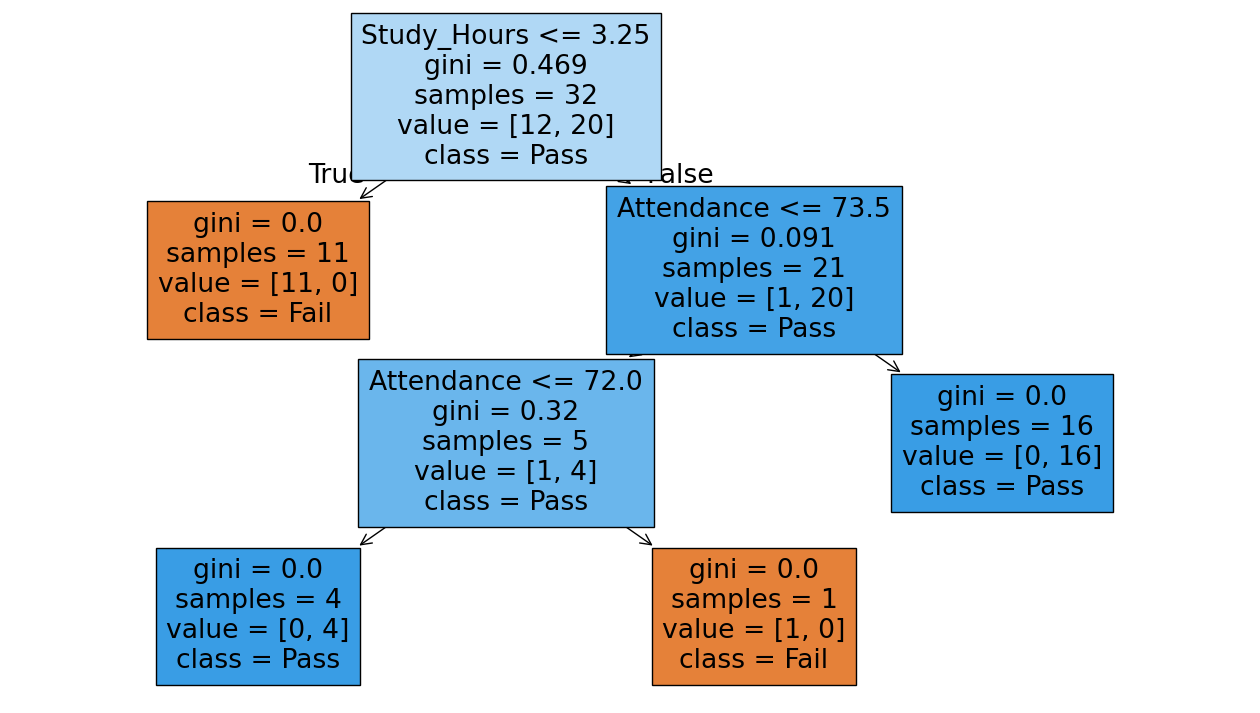

In [15]:
plt.figure(figsize=(16, 9))

plot_tree(
    tree,
    feature_names=["Study_Hours", "Attendance"],
    class_names=["Fail", "Pass"],
    filled=True
)

plt.show()


## Reading the Tree

Start at the top.

The first box is the **root node**.

Follow the condition:

- If the condition is true → follow one branch.
- If false → follow the other branch.

Continue until reaching a leaf.

The leaf contains the final prediction.


## Why Is This Powerful?

With a tree, we can often explain a prediction in plain language.

For example:

> The student's attendance was above the learned threshold, so the tree followed one branch and eventually classified the student as Pass.


## Display the Tree as Text

We can also extract the learned rules without a diagram.


In [16]:
tree_rules = export_text(
    tree,
    feature_names=["Study_Hours", "Attendance"]
)

print(tree_rules)


|--- Study_Hours <= 3.25
|   |--- class: 0
|--- Study_Hours >  3.25
|   |--- Attendance <= 73.50
|   |   |--- Attendance <= 72.00
|   |   |   |--- class: 1
|   |   |--- Attendance >  72.00
|   |   |   |--- class: 0
|   |--- Attendance >  73.50
|   |   |--- class: 1



## Why Use `export_text()`?

The diagram is useful for teaching and presentations.

The text version is useful when we want to inspect the learned rules directly or document them.


# Part 6 — How Does a Decision Tree Choose a Question?

The tree does not randomly choose questions.

It searches for splits that make the resulting groups more useful for classification.


## What is a Split?

A **split** divides observations into groups using a feature and a threshold.

For example:

`Attendance <= 72.5`

creates two groups:

- Attendance 72.5 or below
- Attendance above 72.5


## Why Split the Data?

Suppose a group contains a mixture of Pass and Fail students.

A useful split may create smaller groups where the classes are more clearly separated.

The tree repeats this process to improve classification.


## Impurity

A Decision Tree uses a measure of impurity to decide how useful a split is.

A common measure is **Gini impurity**.

You do not need to calculate it manually at this stage.

The important idea is:

> A good split makes the resulting groups more class-consistent.


## Gini Impurity — Beginner View

Imagine a box containing:

`5 Pass`

`5 Fail`

The box is mixed.

Now imagine another box containing:

`10 Pass`

`0 Fail`

The second box is much purer.

A Decision Tree prefers splits that produce purer groups.


## Entropy

Another impurity measure is **entropy**.

Entropy measures uncertainty or disorder in a group.

Think of it simply:

- More mixed classes → more uncertainty.
- Mostly one class → less uncertainty.


## Gini vs Entropy

Scikit-learn uses Gini impurity by default.

You can also choose entropy.

For this beginner lesson, focus on the purpose:

> The criterion helps the tree decide which split is useful.


In [17]:
gini_tree = DecisionTreeClassifier(
    criterion="gini",
    max_depth=3,
    random_state=42
)

gini_tree.fit(X_train, y_train)

print("Gini tree trained.")


Gini tree trained.


## Try Entropy

We can build another tree using entropy.


In [18]:
entropy_tree = DecisionTreeClassifier(
    criterion="entropy",
    max_depth=3,
    random_state=42
)

entropy_tree.fit(X_train, y_train)

entropy_predictions = entropy_tree.predict(X_test)

print(
    "Entropy Accuracy:",
    round(accuracy_score(y_test, entropy_predictions), 3)
)


Entropy Accuracy: 0.875


## Should We Always Choose the Higher Score?

No.

A tiny difference in accuracy does not automatically make one criterion better.

Consider test performance, model complexity, error types, and the real-world problem.


# Part 7 — The Main Problem: Overfitting

Now we reach the most important Decision Tree concept.


## What is Overfitting?

**Overfitting happens when a model learns the training data too closely, including noise or accidental patterns, and then performs poorly on unseen data.**


## Real-Life Analogy

Imagine a student memorizes the exact answers to a practice test.

They score 100% on that practice test.

But when the questions change, they struggle.

The student memorized examples instead of learning the underlying idea.

A very deep Decision Tree can behave similarly.


## Why Trees Overfit

A tree can keep creating more and more branches.

Eventually, it may create rules that are extremely specific to individual training observations.

That can produce:

**Very high training accuracy**

but:

**Lower test accuracy**


## Tree Depth

**Tree depth describes how many levels of decisions the tree can make from the root downward.**

A shallow tree is simple.

A deep tree is more complex.


## `max_depth`

`max_depth` controls the maximum depth of the tree.

For example:

```python
DecisionTreeClassifier(max_depth=3)
```

limits the tree to three levels.


## Why Use `max_depth`?

It gives us a simple way to control model complexity.

Instead of allowing the tree to grow until it can almost memorize the training data, we can stop it earlier.


# Part 8 — Compare Different Tree Depths

Let's train several trees with different maximum depths.

This makes overfitting easier to understand from actual results.


In [19]:
depths = [1, 2, 3, 4, 5, None]

results = []

for depth in depths:
    model = DecisionTreeClassifier(
        max_depth=depth,
        random_state=42
    )

    model.fit(X_train, y_train)

    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    results.append({
        "max_depth": depth,
        "train_accuracy": accuracy_score(y_train, train_pred),
        "test_accuracy": accuracy_score(y_test, test_pred)
    })

depth_results = pd.DataFrame(results)
depth_results


,max_depth,train_accuracy,test_accuracy
0,1.0,0.96875,0.875
1,2.0,0.96875,0.875
2,3.0,1.00000,0.875
3,4.0,1.00000,0.875
4,5.0,1.00000,0.875
5,NaN,1.00000,0.875


## What Should You Look For?

Look at:

- Training accuracy
- Testing accuracy

As depth increases, training performance often improves.

But test performance does not necessarily keep improving.


## Plot the Comparison


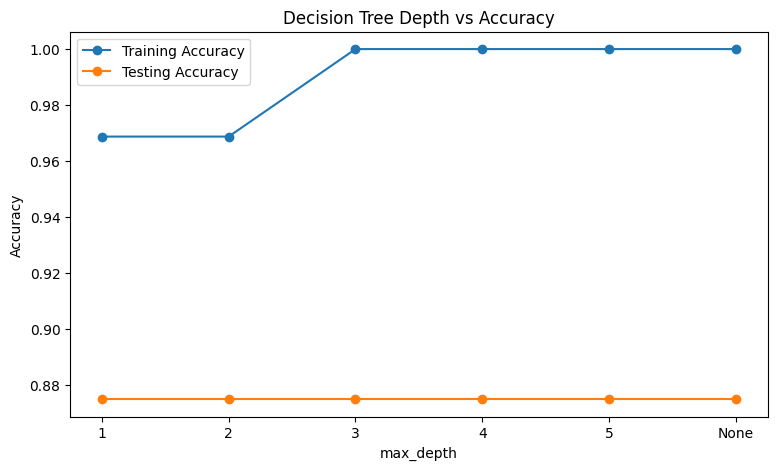

In [20]:
plot_results = depth_results.copy()
plot_results["Depth_Label"] = plot_results["max_depth"].apply(
    lambda d: "None" if pd.isna(d) else str(int(d))
)

plt.figure(figsize=(9, 5))

plt.plot(
    plot_results["Depth_Label"],
    plot_results["train_accuracy"],
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    plot_results["Depth_Label"],
    plot_results["test_accuracy"],
    marker="o",
    label="Testing Accuracy"
)

plt.xlabel("max_depth")
plt.ylabel("Accuracy")
plt.title("Decision Tree Depth vs Accuracy")
plt.legend()
plt.show()


## Interpreting the Plot

A useful pattern to watch for is:

- Very shallow tree → may underfit.
- Moderate depth → may generalize well.
- Very deep tree → may overfit.

The best depth is not necessarily the deepest tree.


## Underfitting

A tree with very little depth may be too simple.

It may not capture enough of the relationship between the features and target.

This is **underfitting**.


## A Balanced Model

Our goal is not:

> Make the tree as complicated as possible.

Our goal is:

> Learn useful patterns that generalize to new data.


# Part 9 — Visualize Shallow vs Deep Trees

Let's compare a shallow tree with an unrestricted tree.


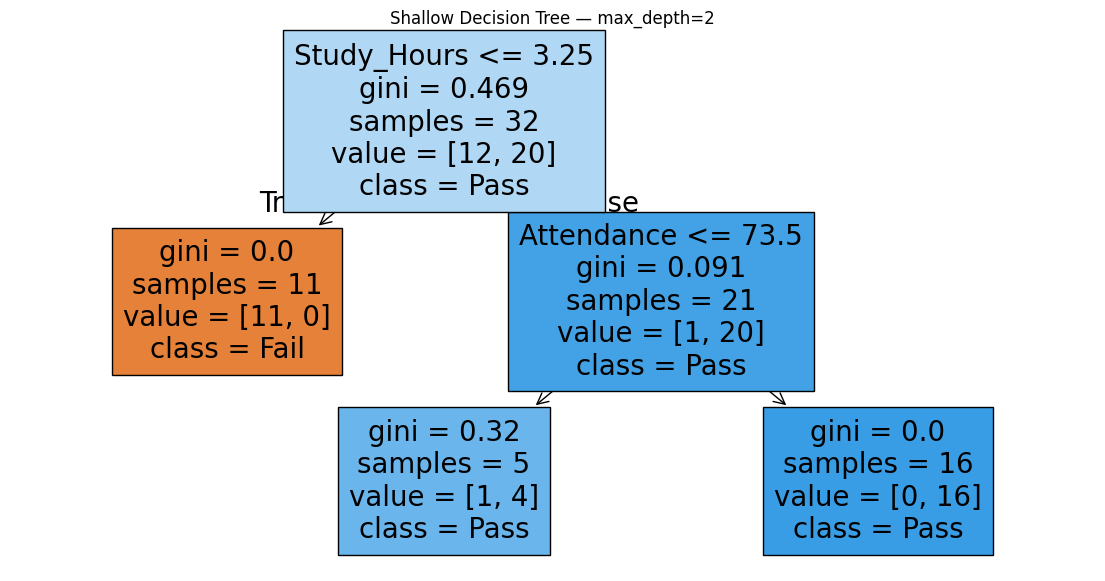

In [21]:
shallow_tree = DecisionTreeClassifier(
    max_depth=2,
    random_state=42
)

shallow_tree.fit(X_train, y_train)

plt.figure(figsize=(14, 7))

plot_tree(
    shallow_tree,
    feature_names=["Study_Hours", "Attendance"],
    class_names=["Fail", "Pass"],
    filled=True
)

plt.title("Shallow Decision Tree — max_depth=2")
plt.show()


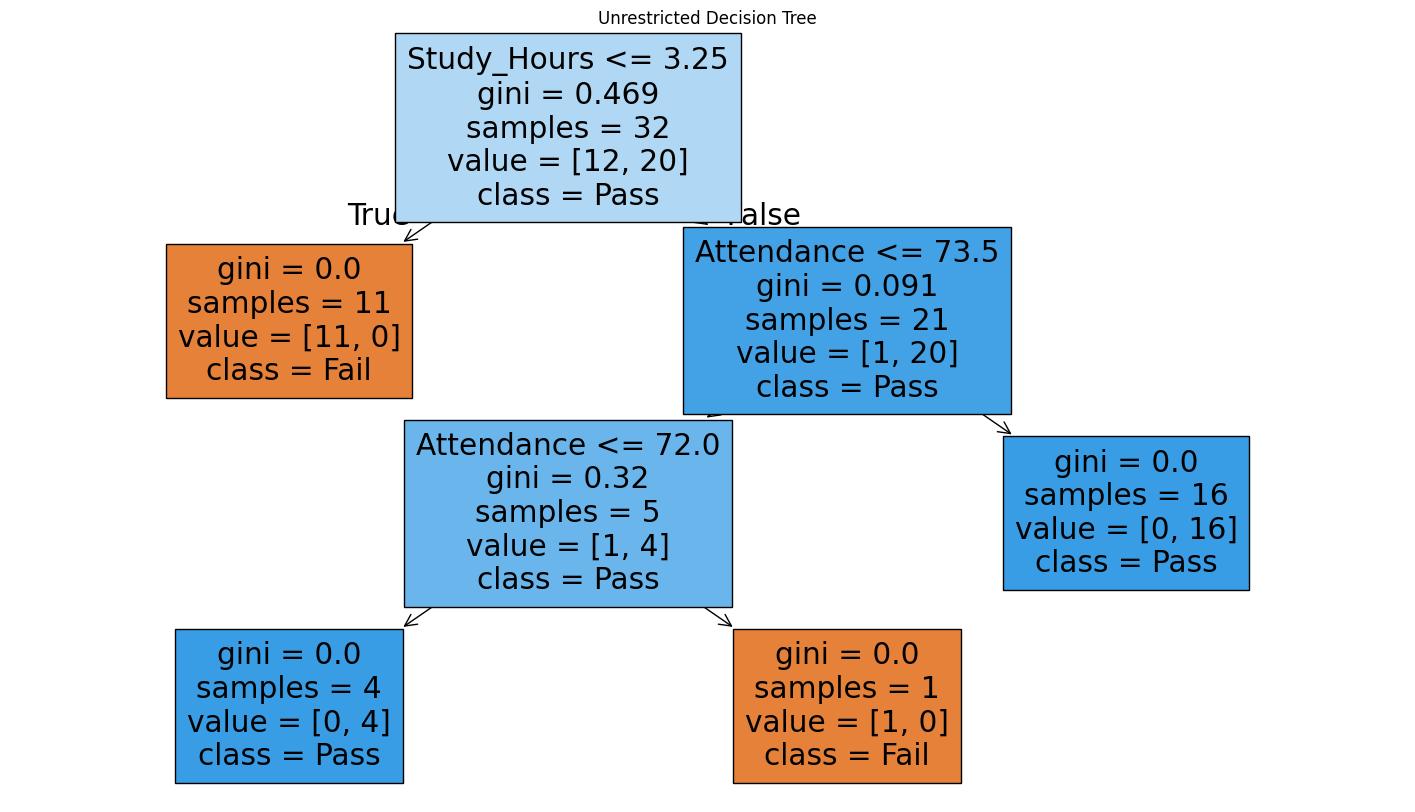

In [22]:
deep_tree = DecisionTreeClassifier(
    random_state=42
)

deep_tree.fit(X_train, y_train)

plt.figure(figsize=(18, 10))

plot_tree(
    deep_tree,
    feature_names=["Study_Hours", "Attendance"],
    class_names=["Fail", "Pass"],
    filled=True
)

plt.title("Unrestricted Decision Tree")
plt.show()


## What Should You Notice?

The unrestricted tree can become much larger.

The shallow tree is easier to understand.

The deeper tree has more opportunities to capture detailed patterns.

More complexity is not automatically better.


# Part 10 — Understanding a Tree Node

When you view the tree, you may see:

- `samples`
- `value`
- `class`
- `gini`


## `samples`

`samples` tells us how many training observations reached that node.

For example:

`samples = 20`

means 20 training observations reached that point.


## `value`

For a binary classification problem, `value` shows how many observations from each class are present.

For example:

`value = [8, 12]`

means:

- 8 observations from class 0
- 12 observations from class 1


## `class`

`class` shows the class the node would predict if an observation stopped there.

It is usually the majority class in that node.


## `gini`

`gini` shows the impurity of the node when the Gini criterion is used.

Lower impurity means the node is more dominated by one class.


# Part 11 — Predict a New Student

Suppose a new student has:

- Study Hours = 6
- Attendance = 85

Let's see what the tree predicts.


In [23]:
new_student = pd.DataFrame({
    "Study_Hours": [6],
    "Attendance": [85]
})

new_prediction = shallow_tree.predict(new_student)
new_probability = shallow_tree.predict_proba(new_student)

print("Predicted class:", new_prediction[0])
print("Class probabilities:", new_probability[0])


Predicted class: 1
Class probabilities: [0. 1.]


## Interpret the Prediction

Remember:

`0 = Fail`

`1 = Pass`

The model's output is a prediction based on the decision rules it learned from the training data.


# Part 12 — Feature Importance

Decision Trees can also tell us how much each feature contributed to the splitting process.


## What is Feature Importance?

**Feature importance is a score describing how useful each feature was to the trained tree's splitting decisions.**

It does not mean:

> "This feature causes the target."

It describes usefulness inside the model.


In [24]:
importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": tree.feature_importances_
})

importance


,Feature,Importance
0,Study_Hours,0.873016
1,Attendance,0.126984


## Visualize Feature Importance


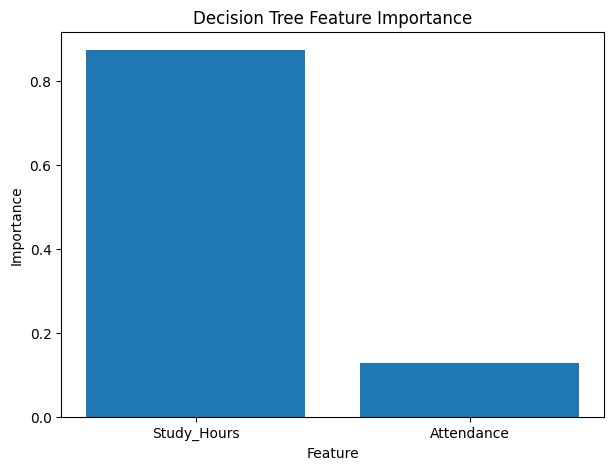

In [25]:
plt.figure(figsize=(7, 5))

plt.bar(
    importance["Feature"],
    importance["Importance"]
)

plt.xlabel("Feature")
plt.ylabel("Importance")
plt.title("Decision Tree Feature Importance")
plt.show()


## Important Caution

A high importance score does not prove causation.

It also does not mean the feature will always be important on another dataset or in another model.


# Part 13 — Example 2: Customer Churn

Let's apply a Decision Tree to a business problem.

Our target is:

`0 = Stayed`

`1 = Churned`


## Load the Dataset


In [26]:
churn = pd.read_csv("customer_churn.csv")
churn.head()


,Customer_ID,Tenure_Months,Monthly_Charges,Support_Calls,Churn
0,C001,2,85,7,1
1,C002,4,80,6,1
2,C003,6,78,8,1
3,C004,8,75,5,0
4,C005,10,72,6,0


## Select Features and Target

We will use:

- Tenure Months
- Monthly Charges
- Support Calls

to predict:

- Churn


In [27]:
X_churn = churn[
    ["Tenure_Months", "Monthly_Charges", "Support_Calls"]
]

y_churn = churn["Churn"]


## Split the Churn Data


In [28]:
Xc_train, Xc_test, yc_train, yc_test = train_test_split(
    X_churn,
    y_churn,
    test_size=0.2,
    random_state=42,
    stratify=y_churn
)


## Train the Churn Decision Tree


In [29]:
churn_tree = DecisionTreeClassifier(
    max_depth=3,
    random_state=42
)

churn_tree.fit(Xc_train, yc_train)

print("Churn Decision Tree trained.")


Churn Decision Tree trained.


## Predict Churn


In [30]:
churn_predictions = churn_tree.predict(Xc_test)
churn_predictions


array([0, 1, 0, 0, 0, 1])

## Evaluate Churn


In [31]:
churn_accuracy = accuracy_score(yc_test, churn_predictions)

print("Churn Accuracy:", round(churn_accuracy, 3))


Churn Accuracy: 1.0


In [32]:
print("Confusion Matrix:")
print(confusion_matrix(yc_test, churn_predictions))

print("\nClassification Report:")
print(classification_report(yc_test, churn_predictions))


Confusion Matrix:
[[4 0]
 [0 2]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00         4
           1       1.00      1.00      1.00         2

    accuracy                           1.00         6
   macro avg       1.00      1.00      1.00         6
weighted avg       1.00      1.00      1.00         6



## Visualize the Churn Tree


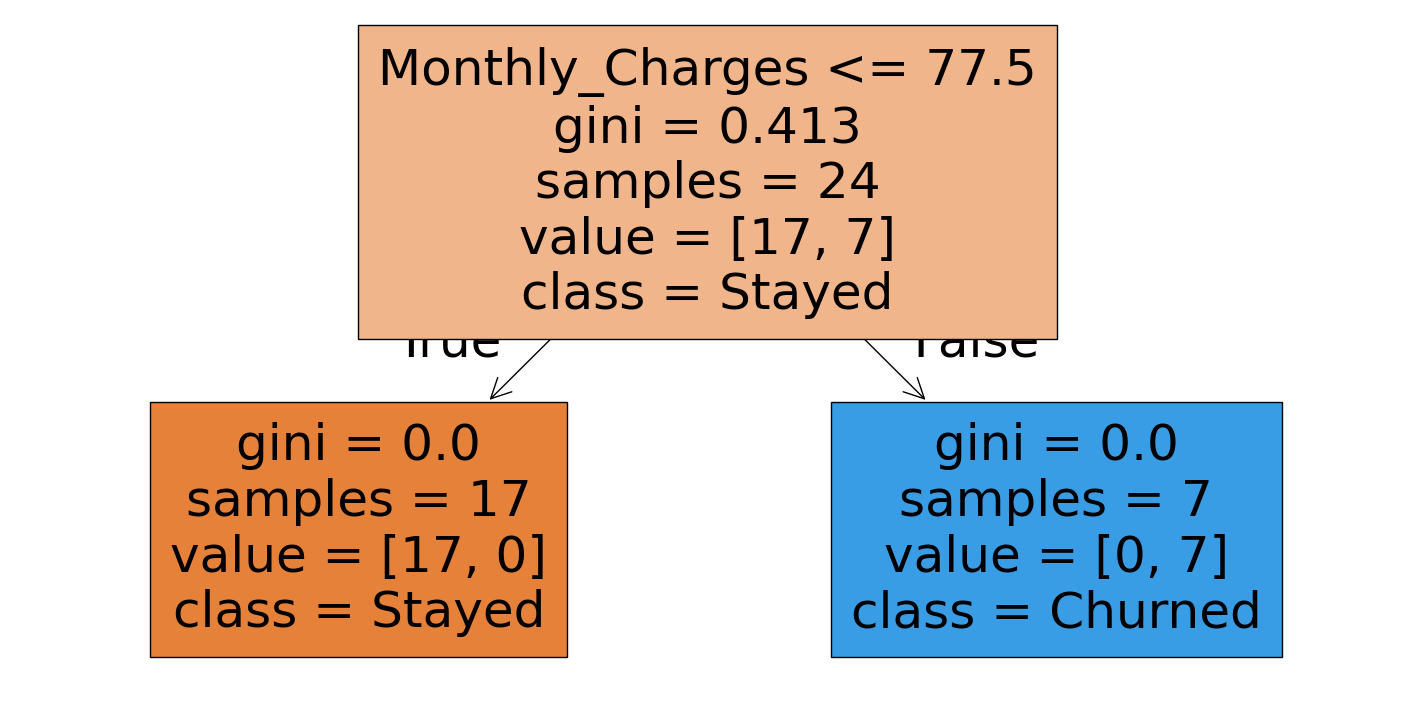

In [33]:
plt.figure(figsize=(18, 9))

plot_tree(
    churn_tree,
    feature_names=[
        "Tenure_Months",
        "Monthly_Charges",
        "Support_Calls"
    ],
    class_names=["Stayed", "Churned"],
    filled=True
)

plt.show()


# Part 14 — Logistic Regression vs Decision Tree

We have now used two classification algorithms on related problems.

Let's compare their thinking styles.


| Logistic Regression | Decision Tree |
|---|---|
| Uses a mathematical relationship | Uses decision rules |
| Produces probabilities | Can produce probabilities |
| Usually learns a linear decision boundary | Can learn non-linear boundaries |
| Often benefits from feature scaling | Usually does not require scaling |
| Less naturally visual as rules | Very easy to visualize |
| Can be interpreted through coefficients | Can be interpreted through paths and splits |


## Which One Is Better?

There is no universal winner.

The correct choice depends on:

- the data,
- the problem,
- interpretability requirements,
- evaluation results,
- and operational needs.


## Compare on the Student Dataset

We already trained Logistic Regression in Day 1.

Let's train a controlled Decision Tree and compare their test accuracy.


In [34]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

student_scaler = StandardScaler()

X_train_scaled = student_scaler.fit_transform(X_train)
X_test_scaled = student_scaler.transform(X_test)

logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

logistic_model.fit(X_train_scaled, y_train)
logistic_predictions = logistic_model.predict(X_test_scaled)

tree_model = DecisionTreeClassifier(
    max_depth=3,
    random_state=42
)

tree_model.fit(X_train, y_train)
tree_predictions = tree_model.predict(X_test)

comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree"
    ],
    "Accuracy": [
        accuracy_score(y_test, logistic_predictions),
        accuracy_score(y_test, tree_predictions)
    ]
})

comparison


,Model,Accuracy
0,Logistic Regression,1.000
1,Decision Tree,0.875


## Important

A higher accuracy on one small dataset does not mean the algorithm is always better.

It only tells us how the models performed under this particular experiment.


# Part 15 — Pruning and Controlling Tree Growth

We already used `max_depth` to limit the tree.

Another important idea is **pruning**.


## What is Pruning?

**Pruning is the process of reducing unnecessary branches in a Decision Tree to make the model simpler and potentially improve generalization.**

Think of pruning as cutting away branches that add complexity without providing enough useful predictive value.


## Why Prune?

A complicated tree may memorize training data.

A simpler tree may generalize better.

The goal is not to make the tree as small as possible.

The goal is to find a useful balance between complexity and performance.


## Cost-Complexity Pruning

Scikit-learn provides **cost-complexity pruning**.

The parameter:

`ccp_alpha`

controls the amount of pruning.

Higher values generally encourage more pruning.


In [35]:
pruned_tree = DecisionTreeClassifier(
    max_depth=5,
    ccp_alpha=0.01,
    random_state=42
)

pruned_tree.fit(X_train, y_train)

pruned_predictions = pruned_tree.predict(X_test)

print(
    "Pruned Tree Accuracy:",
    round(
        accuracy_score(y_test, pruned_predictions),
        3
    )
)


Pruned Tree Accuracy: 0.875


## Do We Need to Manually Choose `ccp_alpha`?

Not necessarily.

In a real project, we can test different values using validation or cross-validation.

For today's lesson, understand the main idea:

> Tree complexity can be controlled instead of allowing the tree to grow without limits.


# Part 16 — Choosing Tree Depth More Carefully

Choosing `max_depth=3` simply because it looks good is not a reliable general method.

A better approach is to evaluate several settings systematically.


## Cross-Validation Preview

**Cross-validation repeatedly trains and evaluates a model on different portions of the training data.**

It gives us a more reliable estimate than relying on one split alone.

We will study cross-validation more deeply later.


In [36]:
from sklearn.model_selection import cross_val_score

depth_values = range(1, 7)
cv_results = []

for depth in depth_values:
    candidate_tree = DecisionTreeClassifier(
        max_depth=depth,
        random_state=42
    )

    scores = cross_val_score(
        candidate_tree,
        X_train,
        y_train,
        cv=5,
        scoring="accuracy"
    )

    cv_results.append({
        "max_depth": depth,
        "mean_cv_accuracy": scores.mean()
    })

cv_results = pd.DataFrame(cv_results)
cv_results


,max_depth,mean_cv_accuracy
0,1,0.971429
1,2,0.971429
2,3,0.938095
3,4,0.938095
4,5,0.938095
5,6,0.938095


## Why Use Cross-Validation?

Instead of asking:

> "Which depth worked best on this one test split?"

we can ask:

> "Which depth performs consistently across several training/validation splits?"

This reduces our dependence on one lucky or unlucky split.


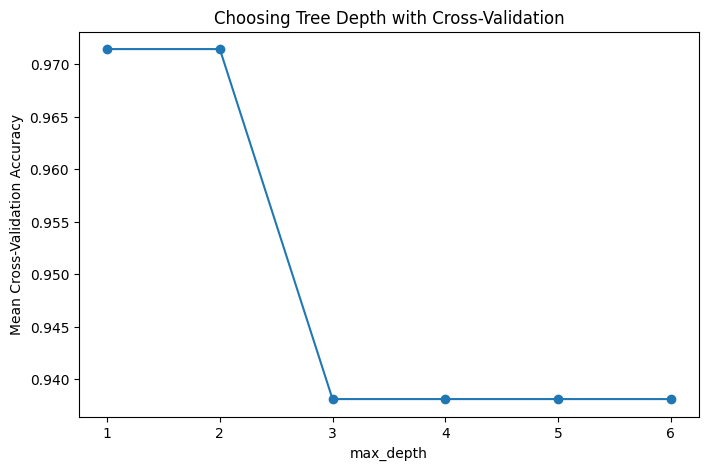

In [37]:
plt.figure(figsize=(8, 5))

plt.plot(
    cv_results["max_depth"],
    cv_results["mean_cv_accuracy"],
    marker="o"
)

plt.xlabel("max_depth")
plt.ylabel("Mean Cross-Validation Accuracy")
plt.title("Choosing Tree Depth with Cross-Validation")
plt.show()


## Important Data-Splitting Rule

We still keep the final test set separate.

Cross-validation is normally performed on the training data while the final test set remains untouched until final evaluation.


# Part 17 — Why `random_state` Again?

`random_state` controls randomness in processes that use randomization.

Using the same value helps us reproduce the same experiment.


In [38]:
tree_a = DecisionTreeClassifier(
    max_depth=3,
    random_state=42
)

tree_b = DecisionTreeClassifier(
    max_depth=3,
    random_state=42
)

tree_a.fit(X_train, y_train)
tree_b.fit(X_train, y_train)

print(
    "Predictions identical:",
    (tree_a.predict(X_test) == tree_b.predict(X_test)).all()
)


Predictions identical: True


# Part 18 — Decision Trees for Regression

Today we are using:

`DecisionTreeClassifier`

because our target is categorical.

Scikit-learn also provides:

`DecisionTreeRegressor`

for continuous numerical predictions.

Example:

> Predict house price using area and number of rooms.

That is regression, so we would use a Decision Tree Regressor.


In [39]:
from sklearn.tree import DecisionTreeRegressor

regression_tree = DecisionTreeRegressor(
    max_depth=3,
    random_state=42
)

print(regression_tree)


DecisionTreeRegressor(max_depth=3, random_state=42)


## Why Are We Not Training It Today?

Week 5 is focused on classification algorithms.

The curriculum specifically requires students to train and visualize a Decision Tree and discuss how `max_depth` affects accuracy and overfitting. fileciteturn21file2L1-L20


# Part 19 — Guided Practice

The first exercises are direct applications.

The later exercises require interpretation.


### Exercise 1 — Build a Decision Tree

Using `students.csv`:

1. Select `Study_Hours` and `Attendance`.
2. Select `Pass` as the target.
3. Split the data.
4. Train a Decision Tree.
5. Predict the test set.
6. Calculate accuracy.

**Estimated Time:** 10 minutes.


In [40]:
# Write your solution here


### Exercise 2 — Visualize the Tree

Visualize your trained tree.

Make sure the diagram includes:

- feature names
- class names
- filled nodes

**Estimated Time:** 8 minutes.


In [41]:
# Write your solution here


### Exercise 3 — Change `max_depth`

Train trees with:

- `max_depth=1`
- `max_depth=2`
- `max_depth=3`
- `max_depth=5`

Record the training and testing accuracy.

**Estimated Time:** 10 minutes.


In [42]:
# Write your solution here


### Exercise 4 — Interpret Overfitting

Look at your results.

Answer:

> At what point does increasing tree depth stop improving test performance?

There may not be a dramatic difference in this small dataset. Explain what you observe rather than forcing a conclusion.


In [43]:
# Write your answer here


### Exercise 5 — Confusion Matrix

Generate the confusion matrix for your chosen tree.

Then explain one possible:

- False Positive
- False Negative

in the context of student results.


In [44]:
# Write your solution here


# Part 20 — Mini Project: Customer Churn

Now work independently with `customer_churn.csv`.

Your goal:

> Predict whether a customer will churn.


## Before You Start

This mini project uses `customer_churn.csv`, which was created back in Week 5 Day 1 (Part 15). If you already have that file in the same folder as this notebook, you're all set.

If you don't, the cell below will check for it and recreate the exact same file automatically, so this notebook can run on its own.

In [45]:
import os
import pandas as pd

if not os.path.exists("customer_churn.csv"):
    # Recreate the same dataset from Week 5 Day 1, Part 15,
    # in case this notebook is run on its own.
    churn_data = {
        "Customer_ID": [f"C{i:03d}" for i in range(1, 31)],
        "Tenure_Months": [
            2, 4, 6, 8, 10, 12, 14, 18, 20, 24,
            3, 5, 7, 9, 11, 15, 17, 19, 22, 26,
            1, 4, 6, 13, 16, 21, 23, 28, 30, 36
        ],
        "Monthly_Charges": [
            85, 80, 78, 75, 72, 70, 68, 65, 62, 60,
            90, 86, 82, 77, 73, 69, 66, 64, 61, 58,
            95, 88, 84, 71, 67, 63, 59, 55, 52, 50
        ],
        "Support_Calls": [
            7, 6, 8, 5, 6, 4, 5, 3, 4, 2,
            9, 7, 6, 5, 5, 4, 3, 3, 2, 2,
            10, 8, 7, 4, 4, 3, 2, 2, 1, 1
        ],
        "Churn": [
            1, 1, 1, 0, 0, 0, 0, 0, 0, 0,
            1, 1, 1, 0, 0, 0, 0, 0, 0, 0,
            1, 1, 1, 0, 0, 0, 0, 0, 0, 0
        ]
    }
    pd.DataFrame(churn_data).to_csv("customer_churn.csv", index=False)
    print("customer_churn.csv was not found - recreated it here.")
else:
    print("customer_churn.csv found - ready to use.")


customer_churn.csv found - ready to use.


## Requirements

Your notebook should contain:

1. Dataset inspection.
2. Feature and target selection.
3. Train/test split.
4. Decision Tree.
5. At least three different `max_depth` values.
6. Accuracy comparison.
7. Confusion matrix.
8. Classification report.
9. Tree visualization.
10. Feature importance.
11. Short explanation of which depth you would choose and why.


In [46]:
# Write your solution here


# Part 21 — Debug This Decision Tree

The code below contains several mistakes.

Find and fix them.


In [47]:
# BUGGY CODE

# X = students[["Study_Hours", "Attendance"]]
# y = students["Pass"]

# X_train, X_test, y_train, y_test = train_test_split(
#     X, y, test_size=0.2, random_state=42
# )

# tree = DecisionTreeClassifier(max_depth=3 random_state=42)

# tree.fit(X_test, y_test)

# predictions = tree.predict(X_train)

# print(accuracy_score(y_train, predictions))

# plt.figure(figsize=(10, 6))
# plot_tree(tree)
# plt.show()


## Debugging Hints

Check:

- the constructor syntax,
- which data should be used for training,
- which data should be used for prediction,
- which actual values should be used for evaluation.


In [48]:
# Write your corrected code here


# Part 22 — Understanding a Prediction Path

A Decision Tree prediction follows a path from the root to a leaf.

This makes the model relatively easy to inspect.


In [49]:
sample = X_test.iloc[[0]]

print("Student:")
display(sample)

print("Prediction:", tree.predict(sample)[0])


Student:


,Study_Hours,Attendance
36,7.0,89


Prediction: 1


## Decision Path

Scikit-learn can identify the nodes an observation passes through.

This is a technical demonstration of the tree's prediction path.


In [50]:
sample_path = tree.decision_path(sample)

print("Nodes visited:")
print(sample_path.toarray())


Nodes visited:
[[1 0 1 0 0 0 1]]


## Important Interpretation

A decision path is not human reasoning.

The tree is following mathematical split rules learned from data.

We translate those rules into human-readable explanations.


# Part 23 — Feature Importance Practice

Let's inspect which student feature the tree relied on most.


In [51]:
feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": tree.feature_importances_
})

feature_importance.sort_values(
    "Importance",
    ascending=False
)


,Feature,Importance
0,Study_Hours,0.873016
1,Attendance,0.126984


### Exercise

Which feature has the highest importance?

Write one sentence explaining what that means and one sentence explaining what it does **not** mean.


In [52]:
# Write your answer here


# Part 24 — Final Comparison: Logistic Regression vs Decision Tree

Use the same student dataset to compare both models.


In [53]:
final_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree"
    ],
    "Test Accuracy": [
        accuracy_score(y_test, logistic_predictions),
        accuracy_score(y_test, tree_predictions)
    ]
})

final_comparison


,Model,Test Accuracy
0,Logistic Regression,1.000
1,Decision Tree,0.875


## What Should We Compare?

Do not compare only accuracy.

Also consider:

- interpretability,
- preprocessing requirements,
- model complexity,
- types of errors,
- probability outputs,
- and generalization.


## Quick Decision Guide

A Decision Tree can be useful when:

- rule-like decisions are helpful,
- interpretability matters,
- relationships may be non-linear,
- you want an easily visualized model.

Logistic Regression can be useful when:

- a simple linear classification boundary is appropriate,
- probability-based classification is useful,
- you want a compact baseline model.

These are guidelines, not absolute rules.


# Decision Tree Reference Table

| Concept / Function | What It Does |
|---|---|
| Decision Tree | Makes predictions using learned decision rules |
| Classification | Predicts categories |
| Root Node | First decision in the tree |
| Branch | Path created by a decision |
| Leaf | Final prediction point |
| Split | Divides observations using a feature and threshold |
| Gini | Measures impurity of a node |
| Entropy | Another measure of uncertainty/impurity |
| `DecisionTreeClassifier()` | Creates a classification tree |
| `.fit()` | Trains the tree |
| `.predict()` | Produces class predictions |
| `.predict_proba()` | Produces class probabilities |
| `max_depth` | Limits how deep the tree can grow |
| `random_state` | Makes randomness reproducible |
| `plot_tree()` | Visualizes the trained tree |
| `export_text()` | Displays tree rules as text |
| `feature_importances_` | Shows feature importance scores |
| `accuracy_score()` | Measures overall correctness |
| `confusion_matrix()` | Shows classification errors |
| `classification_report()` | Shows precision, recall, F1-score and support |
| `ccp_alpha` | Controls cost-complexity pruning |
| `cross_val_score()` | Evaluates a model using cross-validation |


# Key Takeaways

✅ A **Decision Tree** makes predictions using a sequence of learned decisions.

✅ The **root** is the first decision.

✅ **Branches** represent possible paths.

✅ **Leaves** represent final predictions.

✅ Decision Trees can capture non-linear relationships.

✅ Decision Trees usually do not require feature scaling.

✅ `max_depth` controls tree complexity.

✅ Very deep trees can **overfit**.

✅ Very shallow trees can **underfit**.

✅ Training accuracy alone is not enough.

✅ Testing performance helps us judge generalization.

✅ Feature importance describes usefulness inside the model; it does not prove causation.

✅ Pruning can reduce unnecessary tree complexity.

✅ A Decision Tree should be evaluated using both performance metrics and the real-world context.


# Assignment

Submit a Jupyter Notebook containing:

1. Dataset description.
2. Decision Tree implementation.
3. Train/test split.
4. Decision Tree model.
5. Accuracy score.
6. Confusion matrix.
7. Classification report.
8. Tree visualization.
9. At least three different `max_depth` experiments.
10. Training vs testing accuracy comparison.
11. Short explanation of overfitting.
12. Feature importance.
13. Short explanation of which tree depth you selected and why.

This directly follows the Week 5 Day 2 curriculum requirement to build and visualize a Decision Tree and discuss how tree depth affects accuracy and overfitting. fileciteturn21file2L1-L20


# Final Reflection

Answer these questions:

1. What is a Decision Tree?
2. What is a root node?
3. What is a leaf?
4. What is a split?
5. Why does a Decision Tree split data?
6. What is Gini impurity?
7. Why do Decision Trees usually not need scaling?
8. What does `max_depth` control?
9. What is overfitting?
10. What is underfitting?
11. Why can a very deep tree be a problem?
12. What is pruning?
13. What does `feature_importances_` tell us?
14. How is a Decision Tree different from Logistic Regression?
15. Why should we evaluate a model on unseen data?


# Preview: Week 6 — Neural Networks Basics

Next, we move beyond traditional Machine Learning models.

We will learn about:

- neurons,
- weights,
- bias,
- activation functions,
- perceptrons,
- and the basic structure of neural networks.

We will start from a simple perceptron before moving to Artificial Neural Networks with Keras.


# Final Knowledge Check

Without looking at the code, explain this workflow:

**Problem → Data → Features & Target → Train/Test Split → Decision Tree → Prediction → Evaluation → Tree Visualization → Depth Control → Overfitting Check**

If you can explain why each step exists, you understand the Decision Tree workflow rather than simply memorizing the code.
